# SY B.Tech — Applied Mathematics Lab
## Complete Worked Practicals with Theory, Code & Explanation

This notebook covers the following practicals in full, with the theory behind each method,
a complete, runnable Python implementation, sample output, and a discussion of how the
concept is used in Computer/IT Engineering:

| No. | Practical |
|---|---|
| (1) 1A | Matrix addition, multiplication, and scalar operations |
| (2) 1B | Eigenvalues/eigenvectors and diagonalization of a matrix |
| (3) 2A | Discrete & continuous random variables (Binomial & Normal distributions) |
| (4) 2C | Central Limit Theorem — simulation and plot |
| (5) 3A | Large sample Z-test for a single mean |
| (6) 3D | F-test for comparison of variances (small samples) |
| (7) 4B | n-step transition probability of a Markov chain |
| (8) 4D | Second-order (higher-order) Markov process simulation |
| (9) 5A | Karl Pearson's coefficient of correlation |
| (10) 5D | Multiple Linear Regression on a dataset |
| (11) 6A | Lagrange's interpolation method |
| (12) 6B | Newton's (divided-difference) interpolation method |

Each section is self-contained: run the cells in order (top to bottom).


# PRACTICAL NO. 1 — Linear Algebra

## 1A: Matrix Addition, Multiplication, and Scalar Operations

**Theory**

A matrix is simply a rectangular table of numbers arranged in rows and columns. Three of the
most fundamental operations on matrices are:

* **Matrix Addition:** Two matrices of the *same size* $m \times n$ are added by adding the
  corresponding entries: $(A+B)_{ij} = A_{ij} + B_{ij}$.
* **Matrix Multiplication:** If $A$ is $m \times n$ and $B$ is $n \times p$ (the number of
  columns of $A$ must equal the number of rows of $B$), the product $C = AB$ is $m \times p$
  with $C_{ij} = \sum_{k=1}^{n} A_{ik}B_{kj}$ — i.e., "row of $A$ dotted with column of $B$".
  Matrix multiplication is **not commutative** in general: $AB \neq BA$.
* **Scalar Multiplication:** Every entry of the matrix is multiplied by a single number
  (scalar) $c$: $(cA)_{ij} = c \cdot A_{ij}$.

**Why it matters in Computer Engineering**

* *Image processing* — an image is stored as a matrix of pixel values; brightness/contrast
  adjustments are scalar operations, and filters/convolutions are matrix operations.
* *Computer graphics* — 2D/3D rotation, scaling, and translation of objects are all expressed
  as matrix multiplications.
* *Neural networks* — each layer computes `output = weights × input + bias`, which is exactly
  matrix multiplication plus a matrix (vector) addition.

Below we implement the operations **from scratch** (pure Python, to understand the mechanics)
and then verify the result using NumPy (the library used in real-world code).


In [ ]:

# ---------------------------------------------------------------
# 1A: Matrix Addition, Multiplication, and Scalar Operations
# ---------------------------------------------------------------

# ---- Pure-Python implementation (shows the underlying mechanics) ----

def add_matrices(A, B):
    """Element-wise addition of two matrices of the same shape."""
    return [[A[i][j] + B[i][j] for j in range(len(A[0]))] for i in range(len(A))]

def multiply_matrices(A, B):
    """Standard row-by-column matrix multiplication A (m x n) . B (n x p)."""
    rows_A, cols_A = len(A), len(A[0])
    rows_B, cols_B = len(B), len(B[0])
    assert cols_A == rows_B, "Number of columns of A must equal number of rows of B"
    result = [[0] * cols_B for _ in range(rows_A)]
    for i in range(rows_A):
        for j in range(cols_B):
            result[i][j] = sum(A[i][k] * B[k][j] for k in range(cols_A))
    return result

def scalar_multiply(matrix, scalar):
    """Multiply every entry of the matrix by a scalar."""
    return [[scalar * x for x in row] for row in matrix]

# Example matrices
A = [[2, 3], [4, 5]]
B = [[1, 0], [2, 1]]
scalar = 3

print("Matrix A            :", A)
print("Matrix B            :", B)
print("A + B                :", add_matrices(A, B))
print("A x B (A*B)          :", multiply_matrices(A, B))
print("B x A (B*A)          :", multiply_matrices(B, A), " <-- shows AB != BA")
print(f"{scalar} x A               :", scalar_multiply(A, scalar))

# ---- Verification using NumPy (the standard tool used in practice) ----
import numpy as np
An = np.array(A)
Bn = np.array(B)
print("\n--- NumPy verification ---")
print("A + B (numpy):\n", An + Bn)
print("A @ B (numpy):\n", An @ Bn)          # matrix multiplication
print("A * B (numpy, element-wise!):\n", An * Bn)   # NOTE: '*' is elementwise, NOT matrix mult
print(f"{scalar} * A (numpy):\n", scalar * An)


Matrix A            : [[2, 3], [4, 5]]
Matrix B            : [[1, 0], [2, 1]]
A + B                : [[3, 3], [6, 6]]
A x B (A*B)          : [[8, 3], [14, 5]]
B x A (B*A)          : [[2, 3], [8, 11]]  <-- shows AB != BA
3 x A               : [[6, 9], [12, 15]]

--- NumPy verification ---
A + B (numpy):
 [[3 3]
 [6 6]]
A @ B (numpy):
 [[ 8  3]
 [14  5]]
A * B (numpy, element-wise!):
 [[2 0]
 [8 5]]
3 * A (numpy):
 [[ 6  9]
 [12 15]]


## 1B: Eigenvalues, Eigenvectors, and Diagonalization

**Theory**

For a square matrix $A$, a non-zero vector $v$ is an **eigenvector** with **eigenvalue**
$\lambda$ if:
$$A v = \lambda v$$
i.e., $A$ only *stretches/shrinks* $v$ (by factor $\lambda$) instead of rotating it.
Eigenvalues are found by solving the **characteristic equation**:
$$\det(A - \lambda I) = 0$$

**Diagonalization:** If an $n\times n$ matrix $A$ has $n$ linearly independent eigenvectors,
it can be written as
$$A = P D P^{-1}$$
where $D$ is a diagonal matrix of eigenvalues and $P$ is the matrix whose columns are the
corresponding eigenvectors. Diagonal form makes repeated operations (like computing $A^k$)
extremely fast, since $A^k = P D^k P^{-1}$ and raising a diagonal matrix to a power is trivial.

**Applications**

* *PCA (Principal Component Analysis)* in machine learning uses eigenvectors of the
  covariance matrix to find directions of maximum variance in data.
* *Google's PageRank* and *Markov chain steady states* rely on the eigenvector for eigenvalue 1.
* *Vibration/structural analysis, stability analysis of control systems.*

We compute eigenvalues/eigenvectors with `numpy.linalg.eig` (works for any size matrix) and
then diagonalize and verify $A = PDP^{-1}$.


In [ ]:

# ---------------------------------------------------------------
# 1B: Eigenvalues / Eigenvectors and Diagonalization
# ---------------------------------------------------------------
import numpy as np

A = np.array([
    [4, 1, 0],
    [2, 3, 0],
    [0, 0, 5]
], dtype=float)

# Step 1: Eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(A)
print("Matrix A:\n", A)
print("\nEigenvalues (lambda):", eigenvalues)
print("\nEigenvectors (as columns of P):\n", eigenvectors)

# Step 2: Build P (eigenvector matrix) and D (diagonal eigenvalue matrix)
P = eigenvectors
D = np.diag(eigenvalues)

# Step 3: Diagonalize: A = P D P^-1  -->  verify by reconstructing A
P_inv = np.linalg.inv(P)
A_reconstructed = P @ D @ P_inv

print("\nDiagonal matrix D:\n", D)
print("\nReconstructed A = P D P^-1:\n", np.round(A_reconstructed, 6))
print("\nMatches original A? ", np.allclose(A, A_reconstructed))

# Step 4: Practical payoff of diagonalization - fast matrix powers, e.g. A^5
A_power5_direct = np.linalg.matrix_power(A, 5)
A_power5_via_D  = P @ np.diag(eigenvalues**5) @ P_inv

print("\nA^5 computed directly:\n", np.round(A_power5_direct, 3))
print("\nA^5 computed via diagonalization (P D^5 P^-1):\n", np.round(A_power5_via_D.real, 3))

Matrix A:
 [[4. 1. 0.]
 [2. 3. 0.]
 [0. 0. 5.]]

Eigenvalues (lambda): [5. 2. 5.]

Eigenvectors (as columns of P):
 [[ 0.70710678 -0.4472136   0.        ]
 [ 0.70710678  0.89442719  0.        ]
 [ 0.          0.          1.        ]]

Diagonal matrix D:
 [[5. 0. 0.]
 [0. 2. 0.]
 [0. 0. 5.]]

Reconstructed A = P D P^-1:
 [[4. 1. 0.]
 [2. 3. 0.]
 [0. 0. 5.]]

Matches original A?  True

A^5 computed directly:
 [[2094. 1031.    0.]
 [2062. 1063.    0.]
 [   0.    0. 3125.]]

A^5 computed via diagonalization (P D^5 P^-1):
 [[2094. 1031.    0.]
 [2062. 1063.    0.]
 [   0.    0. 3125.]]


# PRACTICAL NO. 2 — Probability Distributions

## 2A: Discrete and Continuous Random Variables (Binomial & Normal Distributions)

**Theory**

* A **discrete random variable** takes countable values. The **Binomial distribution**
  $X \sim B(n,p)$ models the number of successes in $n$ independent trials, each with success
  probability $p$:
  $$P(X=k) = \binom{n}{k} p^k (1-p)^{n-k}, \qquad \text{Mean}=np,\ \text{Variance}=np(1-p)$$
* A **continuous random variable** takes any value in an interval. The **Normal (Gaussian)
  distribution** $X \sim N(\mu,\sigma^2)$ has probability *density* (not probability mass):
  $$f(x) = \frac{1}{\sigma\sqrt{2\pi}} e^{-\frac{(x-\mu)^2}{2\sigma^2}}$$

**Applications**

* Binomial: modelling number of defective items in a batch, packet-loss counts in networking,
  pass/fail of test cases.
* Normal: modelling measurement noise, sensor errors, exam scores; foundational for
  statistics/ML (e.g. Gaussian Naive Bayes, noise models in signal processing).

Below we compute the PMF of a Binomial variable and the PDF of a Normal variable, verify their
mean/variance formulas, and plot both.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, norm

# ---------- Discrete: Binomial distribution ----------
n, p = 10, 0.4                      # 10 trials, success probability 0.4
k_values = np.arange(0, n + 1)
pmf = binom.pmf(k_values, n, p)      # P(X = k) for each k
print(pmf)

[6.04661760e-03 4.03107840e-02 1.20932352e-01 2.14990848e-01
 2.50822656e-01 2.00658125e-01 1.11476736e-01 4.24673280e-02
 1.06168320e-02 1.57286400e-03 1.04857600e-04]


Binomial distribution B(n=10, p=0.4)
  P(X= 0) = 0.0060
  P(X= 1) = 0.0403
  P(X= 2) = 0.1209
  P(X= 3) = 0.2150
  P(X= 4) = 0.2508
  P(X= 5) = 0.2007
  P(X= 6) = 0.1115
  P(X= 7) = 0.0425
  P(X= 8) = 0.0106
  P(X= 9) = 0.0016
  P(X=10) = 0.0001

Theoretical mean  (n*p)      = 4.0
Simulated  mean (10000 draws) = 3.9972
Theoretical variance n*p*(1-p) = 2.4
Simulated  variance            = 2.3875

Normal distribution N(mu=0, sigma=1)
P(-1 < X < 1) = 0.6827  (theoretical ~ 0.6827, the '68%% rule')


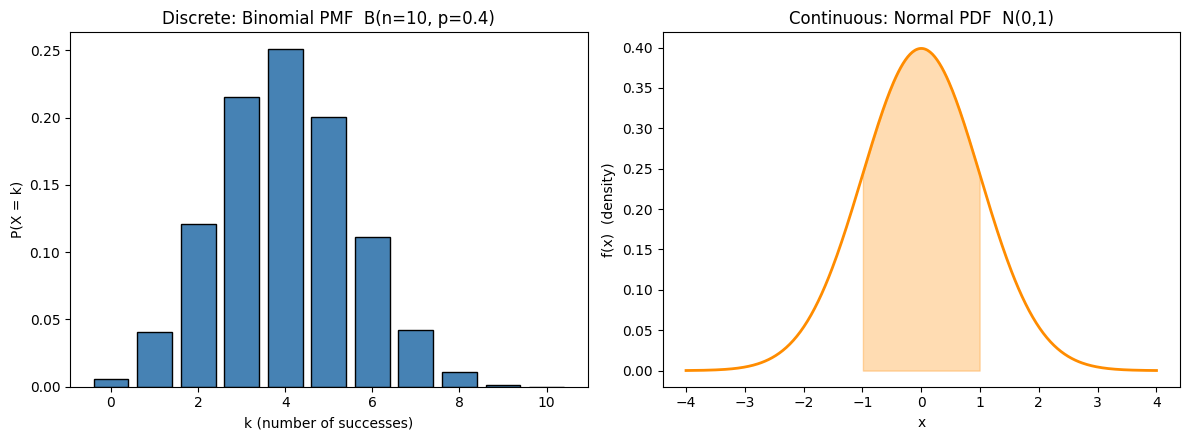

In [ ]:
# ---------------------------------------------------------------
# 2A: Binomial (discrete) & Normal (continuous) random variables
# ---------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom, norm

# ---------- Discrete: Binomial distribution ----------
n, p = 10, 0.4                      # 10 trials, success probability 0.4
k_values = np.arange(0, n + 1)
pmf = binom.pmf(k_values, n, p)      # P(X = k) for each k

print("Binomial distribution B(n=10, p=0.4)")
for k, prob in zip(k_values, pmf):
    print(f"  P(X={k:2d}) = {prob:.4f}")

print(f"\nTheoretical mean  (n*p)      = {n*p}")
print(f"Simulated  mean (10000 draws) = {np.mean(np.random.binomial(n, p, 10000)):.4f}")
print(f"Theoretical variance n*p*(1-p) = {n*p*(1-p)}")
print(f"Simulated  variance            = {np.var(np.random.binomial(n, p, 10000)):.4f}")

# ---------- Continuous: Normal distribution ----------
mu, sigma = 0, 1                    # standard normal
x_values = np.linspace(-4, 4, 400)
pdf = norm.pdf(x_values, mu, sigma)

# P(a < X < b) via CDF, e.g. P(-1 < X < 1)
prob_within_1sd = norm.cdf(1, mu, sigma) - norm.cdf(-1, mu, sigma)
print(f"\nNormal distribution N(mu=0, sigma=1)")
print(f"P(-1 < X < 1) = {prob_within_1sd:.4f}  (theoretical ~ 0.6827, the '68%% rule')")

# ---------- Plot both side-by-side ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(k_values, pmf, color="steelblue", edgecolor="black")
axes[0].set_title("Discrete: Binomial PMF  B(n=10, p=0.4)")
axes[0].set_xlabel("k (number of successes)")
axes[0].set_ylabel("P(X = k)")

axes[1].plot(x_values, pdf, color="darkorange", linewidth=2)
axes[1].fill_between(x_values, pdf, where=(x_values >= -1) & (x_values <= 1),
                      color="darkorange", alpha=0.3)
axes[1].set_title("Continuous: Normal PDF  N(0,1)")
axes[1].set_xlabel("x")
axes[1].set_ylabel("f(x)  (density)")

plt.tight_layout()
plt.show()


## 2C: Central Limit Theorem (CLT) — Simulation and Plot

**Theory**

The **Central Limit Theorem** states that if we repeatedly draw random samples of size $n$
(large enough, typically $n \ge 30$) from *any* population — no matter its original shape —
and compute the sample mean each time, the distribution of those sample means will approach a
**Normal distribution**, centered at the population mean $\mu$, with standard deviation
(the *standard error*) $\sigma/\sqrt{n}$.

This is one of the most important results in statistics because it justifies using
normal-distribution-based tests (Z-tests, confidence intervals) even when the underlying data
is not normal.

**Applications**

* Justifies A/B testing and confidence-interval estimation in software/analytics products.
* Underpins quality-control sampling in manufacturing.
* Basis for bootstrapping and many statistical-inference methods used in data science.

Below we start from a **non-normal** population (Uniform distribution) and show that the
sampling distribution of the mean is nevertheless approximately normal.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Step 1: A clearly NON-normal population -- Uniform[0, 1]
population = np.random.uniform(0, 1, 100000)
print(population)
print(len(population))

[0.16970028 0.97176225 0.80120271 ... 0.68292485 0.17595724 0.9493568 ]
100000



=====
1000
=====

Population mean                      : 0.5009
Population std dev                   : 0.2888
Mean of the 1000 sample means         : 0.5000  (should be close to population mean)
Std dev of the 1000 sample means      : 0.0536
Theoretical standard error (sigma/√n) : 0.0527  (should match line above)


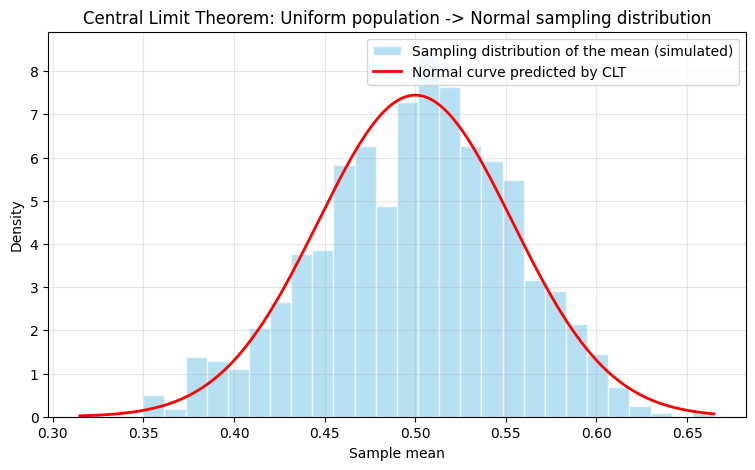

In [ ]:

# ---------------------------------------------------------------
# 2C: Central Limit Theorem - simulation and plot
# ---------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Step 1: A clearly NON-normal population -- Uniform[0, 1]
population = np.random.uniform(0, 1, 100000)

# Step 2: Repeatedly draw samples and record the sample mean each time
sample_size = 30      # size of each sample (n >= 30 is the usual rule of thumb)
num_samples = 1000    # how many sample means we collect

sample_means = np.array([
    np.mean(np.random.choice(population, sample_size))
    for _ in range(num_samples)
])

print()
print("=====")
#print("SAMPLE MEANS:", sample_means)
print(len(sample_means))
print("=====")
print()


# Step 3: Compare the empirical distribution of sample means to the CLT prediction
mean_of_means = np.mean(sample_means)
std_of_means  = np.std(sample_means)
theoretical_se = np.std(population) / np.sqrt(sample_size)   # sigma / sqrt(n)

print(f"Population mean                      : {np.mean(population):.4f}")
print(f"Population std dev                   : {np.std(population):.4f}")
print(f"Mean of the 1000 sample means         : {mean_of_means:.4f}  (should be close to population mean)")
print(f"Std dev of the 1000 sample means      : {std_of_means:.4f}")
print(f"Theoretical standard error (sigma/√n) : {theoretical_se:.4f}  (should match line above)")

# Step 4: Plot histogram of sample means vs. the normal curve CLT predicts
x = np.linspace(min(sample_means), max(sample_means), 500)
pdf = norm.pdf(x, mean_of_means, std_of_means)

plt.figure(figsize=(9, 5))
plt.hist(sample_means, bins=30, density=True, alpha=0.6, color="skyblue",
         edgecolor="white", label="Sampling distribution of the mean (simulated)")
plt.plot(x, pdf, "r", linewidth=2, label="Normal curve predicted by CLT")
plt.title("Central Limit Theorem: Uniform population -> Normal sampling distribution")
plt.xlabel("Sample mean")
plt.ylabel("Density")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# PRACTICAL NO. 3 — Hypothesis Testing

## 3A: Large Sample Test for a Single Mean (Z-test)

**Theory**

Used when we want to test whether a population mean equals some hypothesized value $\mu_0$,
given a **large** sample ($n \ge 30$), so that the sample mean is (by the CLT) approximately
normally distributed.

* **Null hypothesis** $H_0: \mu = \mu_0$
* **Test statistic:**
  $$Z = \frac{\bar{x} - \mu_0}{\sigma/\sqrt{n}}$$
  (population $\sigma$ used if known; otherwise sample standard deviation $s$ is a good
  large-sample approximation).
* Compare $|Z|$ to the critical value $Z_{\alpha/2}$ (e.g. 1.96 for $\alpha=0.05$,
  two-tailed), or equivalently compare the p-value to $\alpha$.

**Applications:** Quality control (is the average weight/size of a manufactured batch equal to
spec?), performance testing (is average response time equal to an SLA target?), A/B testing.


In [ ]:
# ---------------------------------------------------------------
# 3A: Large Sample Z-test for a Single Mean
# ---------------------------------------------------------------
import numpy as np
from scipy.stats import norm

def z_test_single_mean(sample, mu0, sigma=None, alpha=0.05, alternative="two-sided"):
    """
    Large-sample Z-test for H0: population mean = mu0.

    sample      : array-like sample data
    mu0         : hypothesized population mean
    sigma       : population std dev if known; otherwise sample std dev is used
    alpha       : significance level
    alternative : 'two-sided', 'greater', or 'less'
    """
    sample = np.asarray(sample, dtype=float)
    n = len(sample)
    x_bar = sample.mean()
    if sigma is None:
        sigma = sample.std(ddof=1)          # sample standard deviation

    z_stat = (x_bar - mu0) / (sigma / np.sqrt(n))

    if alternative == "two-sided":
        p_value = 2 * (1 - norm.cdf(abs(z_stat)))
    elif alternative == "greater":
        p_value = 1 - norm.cdf(z_stat)
    elif alternative == "less":
        p_value = norm.cdf(z_stat)
    else:
        raise ValueError("alternative must be 'two-sided', 'greater', or 'less'")

    reject = p_value <= alpha
    return {
        "n": n,
        "Sample Mean": round(x_bar, 4),
        "Hypothesized Mean": mu0,
        "Z-statistic": round(z_stat, 4),
        "p-value": round(p_value, 6),
        "alpha": alpha,
        "Conclusion": "Reject H0" if reject else "Fail to Reject H0",
    }

# Example: A machine is supposed to fill bottles with 50 ml on average.
# 40 bottles were sampled (n=40 => "large sample").
np.random.seed(1)
data = np.random.normal(loc=50.6, scale=2.0, size=40)   # simulated sample
mu0 = 50

result = z_test_single_mean(data, mu0, alpha=0.05, alternative="two-sided")
for k, v in result.items():
    print(f"{k:20s}: {v}")

print("\nInterpretation: since the p-value is compared against alpha = 0.05,")
print("we", "REJECT" if result["Conclusion"] == "Reject H0" else "DO NOT REJECT",
      "the claim that the true mean fill volume is 50 ml.")


n                   : 40
Sample Mean         : 50.4208
Hypothesized Mean   : 50
Z-statistic         : 1.3622
p-value             : 0.17314
alpha               : 0.05
Conclusion          : Fail to Reject H0

Interpretation: since the p-value is compared against alpha = 0.05,
we DO NOT REJECT the claim that the true mean fill volume is 50 ml.


In [ ]:
import builtins
print(dir(builtins))

['ArithmeticError', 'AssertionError', 'AttributeError', 'BaseException', 'BaseExceptionGroup', 'BlockingIOError', 'BrokenPipeError', 'BufferError', 'BytesWarning', 'ChildProcessError', 'ConnectionAbortedError', 'ConnectionError', 'ConnectionRefusedError', 'ConnectionResetError', 'DeprecationWarning', 'EOFError', 'Ellipsis', 'EncodingWarning', 'EnvironmentError', 'Exception', 'ExceptionGroup', 'False', 'FileExistsError', 'FileNotFoundError', 'FloatingPointError', 'FutureWarning', 'GeneratorExit', 'IOError', 'ImportError', 'ImportWarning', 'IndentationError', 'IndexError', 'InterruptedError', 'IsADirectoryError', 'KeyError', 'KeyboardInterrupt', 'LookupError', 'MemoryError', 'ModuleNotFoundError', 'NameError', 'None', 'NotADirectoryError', 'NotImplemented', 'NotImplementedError', 'OSError', 'OverflowError', 'PendingDeprecationWarning', 'PermissionError', 'ProcessLookupError', 'PythonFinalizationError', 'RecursionError', 'ReferenceError', 'ResourceWarning', 'RuntimeError', 'RuntimeWarning

In [ ]:
print(dir(list))

['__add__', '__class__', '__class_getitem__', '__contains__', '__delattr__', '__delitem__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__iadd__', '__imul__', '__init__', '__init_subclass__', '__iter__', '__le__', '__len__', '__lt__', '__mul__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__reversed__', '__rmul__', '__setattr__', '__setitem__', '__sizeof__', '__str__', '__subclasshook__', 'append', 'clear', 'copy', 'count', 'extend', 'index', 'insert', 'pop', 'remove', 'reverse', 'sort']


In [ ]:
import numpy
print(dir(numpy))

['False_', 'ScalarType', 'True_', '_CopyMode', '_NoValue', '__NUMPY_SETUP__', '__all__', '__array_api_version__', '__array_namespace_info__', '__builtins__', '__cached__', '__config__', '__dir__', '__doc__', '__expired_attributes__', '__file__', '__former_attrs__', '__future_scalars__', '__getattr__', '__loader__', '__name__', '__numpy_submodules__', '__package__', '__path__', '__spec__', '__version__', '_array_api_info', '_core', '_distributor_init', '_expired_attrs_2_0', '_get_promotion_state', '_globals', '_int_extended_msg', '_mat', '_msg', '_no_nep50_warning', '_pyinstaller_hooks_dir', '_pytesttester', '_set_promotion_state', '_specific_msg', '_type_info', '_typing', '_utils', 'abs', 'absolute', 'acos', 'acosh', 'add', 'all', 'allclose', 'amax', 'amin', 'angle', 'any', 'append', 'apply_along_axis', 'apply_over_axes', 'arange', 'arccos', 'arccosh', 'arcsin', 'arcsinh', 'arctan', 'arctan2', 'arctanh', 'argmax', 'argmin', 'argpartition', 'argsort', 'argwhere', 'around', 'array', 'arr

In [ ]:
import numpy as np
np.random.seed(1)
data = np.random.normal(loc=50.6, scale=2.0, size=2)   # simulated sample
print(data)

[53.84869073 49.37648717]


## 3D: F-test for Comparison of Variances (Small Samples)

**Theory**

The **F-test** checks whether **two populations have equal variances**, i.e.
$H_0: \sigma_1^2 = \sigma_2^2$ vs $H_1: \sigma_1^2 \neq \sigma_2^2$. It is commonly used
*before* a two-sample t-test, to decide whether "equal variance" or "unequal variance" t-test
should be applied.

* **Test statistic:**
  $$F = \frac{s_1^2}{s_2^2}$$
  where $s_1^2$ is the **larger** sample variance (by convention we put the larger variance on
  top so $F \ge 1$), with degrees of freedom $(n_1-1, n_2-1)$.
* Under $H_0$, $F$ follows an **F-distribution**. Reject $H_0$ if $F$ exceeds the critical
  value $F_{\alpha/2}(n_1-1, n_2-1)$, or if the p-value $\le \alpha$.

**Applications:** Comparing consistency/precision of two machines, two manufacturing
processes, or two algorithms' timing variability, before deciding which comparison test
(t-test variant) is valid.


In [ ]:
# ---------------------------------------------------------------
# 3D: F-test for Comparison of Variances (small samples)
# ---------------------------------------------------------------
import numpy as np
from scipy.stats import f as f_dist

def f_test_variances(sample1, sample2, alpha=0.05):
    """
    F-test for H0: variance(sample1) == variance(sample2).
    Puts the larger sample variance in the numerator so F >= 1.
    """
    s1 = np.asarray(sample1, dtype=float)
    s2 = np.asarray(sample2, dtype=float)

    var1, var2 = s1.var(ddof=1), s2.var(ddof=1)
    n1, n2 = len(s1), len(s2)

    # Ensure numerator is the larger variance (standard convention)
    if var1 >= var2:
        F = var1 / var2
        df1, df2 = n1 - 1, n2 - 1
    else:
        F = var2 / var1
        df1, df2 = n2 - 1, n1 - 1

    # Two-tailed p-value
    p_value = 2 * min(f_dist.cdf(F, df1, df2), 1 - f_dist.cdf(F, df1, df2))
    critical_value = f_dist.ppf(1 - alpha / 2, df1, df2)
    reject = F > critical_value

    return {
        "Variance 1": round(var1, 4),
        "Variance 2": round(var2, 4),
        "F-statistic": round(F, 4),
        "df1, df2": (df1, df2),
        "Critical F (alpha/2)": round(critical_value, 4),
        "p-value": round(p_value, 6),
        "Conclusion": "Reject H0 (variances differ)" if reject else "Fail to Reject H0 (variances equal)",
    }

# Example: Precision (variability) of two machines producing the same part (small samples)
machine_A = [10.2, 9.8, 10.5, 10.1, 9.9, 10.3, 10.0]     # n1 = 7
machine_B = [9.5, 10.6, 9.2, 10.8, 9.4, 10.9, 9.1]       # n2 = 7 (visibly more spread out)

result = f_test_variances(machine_A, machine_B, alpha=0.05)
for k, v in result.items():
    print(f"{k:22s}: {v}")

print("\nInterpretation: F compares the spread (variance) of the two machines' output.")
print("A large F far from 1, exceeding the critical value, means the machines differ")
print("significantly in consistency/precision, not just in average output.")

Variance 1            : 0.0581
Variance 2            : 0.639
F-statistic           : 11.0
df1, df2              : (6, 6)
Critical F (alpha/2)  : 5.8198
p-value               : 0.010176
Conclusion            : Reject H0 (variances differ)

Interpretation: F compares the spread (variance) of the two machines' output.
A large F far from 1, exceeding the critical value, means the machines differ
significantly in consistency/precision, not just in average output.


In [ ]:
vehicle = {'brand':'tesla', 'model':2026, 'price':287000}
print(vehicle)
print(vehicle.keys())
print(vehicle.values())
print(vehicle.items())

{'brand': 'tesla', 'model': 2026, 'price': 287000}
dict_keys(['brand', 'model', 'price'])
dict_values(['tesla', 2026, 287000])
dict_items([('brand', 'tesla'), ('model', 2026), ('price', 287000)])


# PRACTICAL NO. 4 — Stochastic Processes & Markov Chains

## 4B: n-Step Transition Probability

**Theory**

A **Markov chain** is a sequence of random states where the probability of moving to the next
state depends *only* on the current state (the "memoryless" property), captured in a
**transition matrix** $P$, where $P_{ij}$ = probability of moving from state $i$ to state $j$
in one step.

The probability of moving from state $i$ to state $j$ in exactly $n$ steps is given by the
$(i,j)$ entry of the matrix $P$ raised to the power $n$:
$$P^{(n)} = P^n$$

**Applications:** Google PageRank (web-surfer model), predicting weather sequences, modelling
user navigation on a website/app, queueing systems, genetics (Markov models of DNA sequences).



1-step transition matrix P^1:
[[0.7 0.2 0.1]
 [0.1 0.6 0.3]
 [0.4 0.2 0.4]]

2-step transition matrix P^2:
[[0.55 0.28 0.17]
 [0.25 0.44 0.31]
 [0.46 0.28 0.26]]

5-step transition matrix P^5:
[[0.4378 0.3299 0.2323]
 [0.4119 0.3402 0.2479]
 [0.4353 0.3299 0.2347]]

10-step transition matrix P^10:
[[0.4287 0.3333 0.238 ]
 [0.4284 0.3334 0.2382]
 [0.4287 0.3333 0.238 ]]

20-step transition matrix P^20:
[[0.4286 0.3333 0.2381]
 [0.4286 0.3333 0.2381]
 [0.4286 0.3333 0.2381]]

Example reading: P^5[0][2] = probability of Rainy in 5 steps, given it is Sunny today.


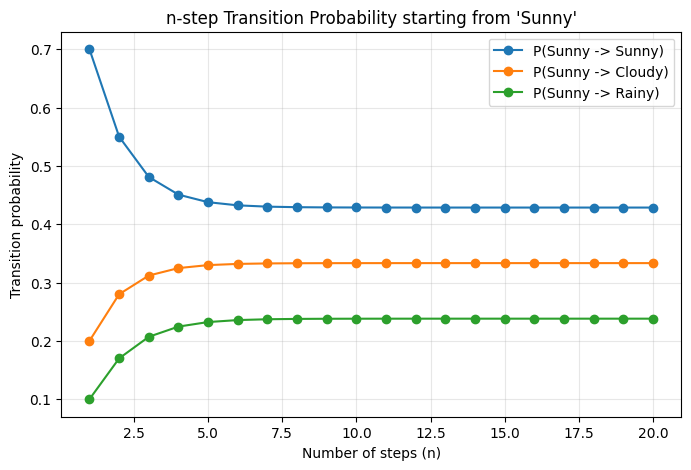


Note: as n grows large, every row of P^n converges to the same values —
this limiting row is the Markov chain's steady-state (stationary) distribution.


In [ ]:

# ---------------------------------------------------------------
# (7) 4B: n-step Transition Probability of a Markov Chain
# ---------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt

def validate_transition_matrix(P):
    """A valid transition matrix: square, non-negative entries, rows sum to 1."""
    P = np.array(P, dtype=float)
    if P.ndim != 2 or P.shape[0] != P.shape[1]:
        raise ValueError("Transition matrix must be square (n x n).")
    if not np.allclose(P.sum(axis=1), 1):
        raise ValueError("Each row of the transition matrix must sum to 1.")
    if np.any(P < 0):
        raise ValueError("Transition matrix cannot have negative entries.")
    if np.any(P > 1):
        raise ValueError("Transition matrix cannot have entries greater than 1.")
    return P

def n_step_transition_probability(P, n):
    """n-step transition matrix = P raised to the power n."""
    P = validate_transition_matrix(P)
    return np.linalg.matrix_power(P, n)

# 3-state weather-style Markov chain: states = Sunny(0), Cloudy(1), Rainy(2)
P = np.array([
    [0.7, 0.2, 0.1],
    [0.1, 0.6, 0.3],
    [0.4, 0.2, 0.4],
])
state_names = ["Sunny", "Cloudy", "Rainy"]

for n in [1, 2, 5, 10, 20]:
    Pn = n_step_transition_probability(P, n)
    print(f"\n{n}-step transition matrix P^{n}:\n{np.round(Pn, 4)}")

print("\nExample reading: P^5[0][2] = probability of Rainy in 5 steps, given it is Sunny today.")

# Visualise how P(state | started Sunny) evolves with n
max_n = 20
evolution = np.array([n_step_transition_probability(P, n)[0] for n in range(1, max_n + 1)])

plt.figure(figsize=(8, 5))
for i, name in enumerate(state_names):
    plt.plot(range(1, max_n + 1), evolution[:, i], marker="o", label=f"P(Sunny -> {name})")
plt.xlabel("Number of steps (n)")
plt.ylabel("Transition probability")
plt.title("n-step Transition Probability starting from 'Sunny'")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("\nNote: as n grows large, every row of P^n converges to the same values —")
print("this limiting row is the Markov chain's steady-state (stationary) distribution.")

## 4D: Simulating a Higher-Order (Second-Order) Markov Process

**Theory**

A **first-order** Markov chain assumes the next state depends only on the *current* state.
A **second-order** Markov chain relaxes this slightly: the next state depends on the **last
two** states, $P(X_{t+1} \mid X_t, X_{t-1})$. This is still "Markov" in a generalized sense —
memory is finite (length 2) rather than infinite.

A standard trick to simulate/analyze a second-order chain is to convert it into an
equivalent **first-order** chain whose states are *pairs* of the original states,
i.e. new state $= (X_{t-1}, X_t)$. This is exactly what we do below.

**Applications:** Text/language modelling (predicting the next word from the previous two
words — bigram-conditioned models), DNA sequence analysis, more realistic weather/traffic
models where "yesterday and today" jointly influence "tomorrow".


**Read Explanation from here:**

https://chatgpt.com/share/6acefc92-a204-83ec-924c-0ac37c2141f1

In [ ]:
from collections import defaultdict, Counter
import numpy as np

# Step 1: Historical weather observations
weather = [
    "Sunny", "Cloudy", "Rainy", "Rainy",
    "Cloudy", "Sunny", "Cloudy", "Rainy",
    "Sunny", "Sunny", "Cloudy", "Rainy",
    "Rainy", "Cloudy", "Sunny", "Cloudy"
]

# Step 2: Count transitions based on previous TWO states
transition_counts = defaultdict(Counter)

for i in range(2, len(weather)):
    previous_two = (weather[i - 2], weather[i - 1])
    next_state = weather[i]
    transition_counts[previous_two][next_state] += 1

# Step 3: Convert counts into probabilities
transition_probabilities = {}

for pair, counts in transition_counts.items():
    total = sum(counts.values())

    transition_probabilities[pair] = {
        state: count / total
        for state, count in counts.items()
    }

# Display the learned probabilities
print("Learned transition probabilities:")

for pair, probs in transition_probabilities.items():
    print(f"\n{pair} ->")

    for state, probability in probs.items():
        print(f"  {state}: {probability:.2%}")

# Step 4: Predict the next state
current_pair = (weather[-2], weather[-1])

if current_pair in transition_probabilities:
    probs = transition_probabilities[current_pair]

    states = list(probs.keys())
    probabilities = list(probs.values())

    rng = np.random.default_rng(42)
    prediction = rng.choice(states, p=probabilities)

    print("\nPrevious two states:", current_pair)
    print("Predicted next state:", prediction)
else:
    print("Insufficient data for this pair.")

Learned transition probabilities:

('Sunny', 'Cloudy') ->
  Rainy: 100.00%

('Cloudy', 'Rainy') ->
  Rainy: 66.67%
  Sunny: 33.33%

('Rainy', 'Rainy') ->
  Cloudy: 100.00%

('Rainy', 'Cloudy') ->
  Sunny: 100.00%

('Cloudy', 'Sunny') ->
  Cloudy: 100.00%

('Rainy', 'Sunny') ->
  Sunny: 100.00%

('Sunny', 'Sunny') ->
  Cloudy: 100.00%

Previous two states: ('Sunny', 'Cloudy')
Predicted next state: Rainy


# PRACTICAL NO. 5 — Correlation and Regression Analysis

## 5A: Karl Pearson's Coefficient of Correlation

**Theory**

Karl Pearson's correlation coefficient $r$ measures the strength and direction of the
**linear** relationship between two numeric variables $X$ and $Y$:

$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i-\bar{x})^2}\sqrt{\sum (y_i-\bar{y})^2}}$$

* $r = +1$: perfect positive linear relationship
* $r = -1$: perfect negative linear relationship
* $r = 0$ : no linear relationship
* $|r|$ closer to 1 => stronger linear association.

**Applications:** Feature selection in machine learning (dropping highly-correlated
redundant features), finance (correlation between stock returns), quality analysis
(relationship between two measured process parameters).


**Key Benefits of the Correlation:**


*   Coefficient Quantifies Relationship Direction: Indicates whether variables move together positively or inversely.
* Measures Strength: Shows the exact magnitude of association through values closer to -1 or +1.
* Unit Independent: Remains uninfluenced by the original measurement units of the variables.
* Scale and Origin Invariant: Unaffected by adding, subtracting, multiplying, or dividing data constants.* Calculation Check: Bounded range (-1 to +1) helps spot mathematical errors easily.
* Aids Diversification: Helps investors combine uncorrelated assets to manage portfolio risk.
* Improves Predictions: Enables forecasting trends and behaviors across business, science, and economics.

Pearson correlation coefficient (from scratch) : 0.9949
Pearson correlation coefficient (numpy check)  : 0.9949
Interpretation: a strong positive linear relationship between hours studied and marks.


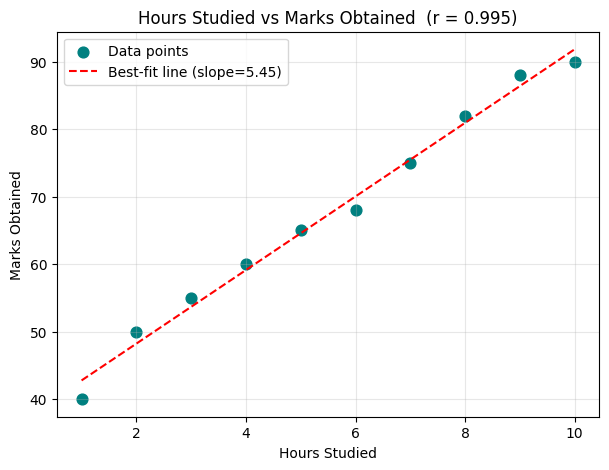

In [ ]:
# ---------------------------------------------------------------
# 5A: Karl Pearson's Coefficient of Correlation
# ---------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
def pearson_correlation(x, y):
    """Compute Karl Pearson's correlation coefficient from first principles."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_mean, y_mean = x.mean(), y.mean()

    numerator = np.sum((x - x_mean) * (y - y_mean))
    denominator = np.sqrt(np.sum((x - x_mean) ** 2)) * np.sqrt(np.sum((y - y_mean) ** 2))
    return numerator / denominator

# Example: hours studied vs marks obtained
hours_studied = [2, 4, 6, 8, 10, 3, 7, 5, 9, 1]
marks_obtained = [50, 60, 68, 82, 90, 55, 75, 65, 88, 40]

r_manual = pearson_correlation(hours_studied, marks_obtained)
r_numpy = np.corrcoef(hours_studied, marks_obtained)[0, 1]   # built-in cross-check

print(f"Pearson correlation coefficient (from scratch) : {r_manual:.4f}")
print(f"Pearson correlation coefficient (numpy check)  : {r_numpy:.4f}")

if r_manual > 0.7:
    strength = "strong positive"
elif r_manual > 0.3:
    strength = "moderate positive"
elif r_manual > -0.3:
    strength = "weak/no linear"
elif r_manual > -0.7:
    strength = "moderate negative"
else:
    strength = "strong negative"
print(f"Interpretation: a {strength} linear relationship between hours studied and marks.")

# Scatter plot with best-fit line for visual confirmation
plt.figure(figsize=(7, 5))
plt.scatter(hours_studied, marks_obtained, color="teal", s=60, label="Data points")
m, c = np.polyfit(hours_studied, marks_obtained, 1)
xs = np.linspace(min(hours_studied), max(hours_studied), 100)
plt.plot(xs, m * xs + c, "r--", label=f"Best-fit line (slope={m:.2f})")
plt.title(f"Hours Studied vs Marks Obtained  (r = {r_manual:.3f})")
plt.xlabel("Hours Studied")
plt.ylabel("Marks Obtained")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5D: Multiple Linear Regression

**Theory**

**Multiple Linear Regression** models a dependent variable $y$ as a linear combination of
*several* independent variables $x_1, x_2, \dots, x_k$:

$$y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_k x_k + \varepsilon$$

The coefficients $\beta_i$ are estimated (typically via least squares) so that the sum of
squared differences between actual and predicted $y$ is minimized. Model quality is judged
using metrics such as **Mean Squared Error (MSE)** and **R² (coefficient of determination)** —
the fraction of variance in $y$ explained by the model.

**Applications:** House-price prediction (from size, location, age, etc.), predicting salaries
from experience/education, demand forecasting from multiple market factors — any scenario
where an outcome depends on several measurable inputs.


Sample of the dataset:
   Size_sqft  Bedrooms  Bathrooms  Distance_km   Price
0       3674         3          3           24  720930
1       1360         3          3           18  278531
2       1794         1          2           15  340979
3       1630         3          3           22  310506
4       1595         3          3           23  311784

Coefficients (beta_1..beta_4): [  199.63  2905.34  4464.79 -1400.55]
Intercept (beta_0)            : -513.53
Mean Squared Error (MSE)      : 41,255,013.99
R^2 Score                     : 0.9990

Fitted regression equation:
Price = -513.53 + (199.63 * Size_sqft) + (2905.34 * Bedrooms) + (4464.79 * Bathrooms) + (-1400.55 * Distance_km)


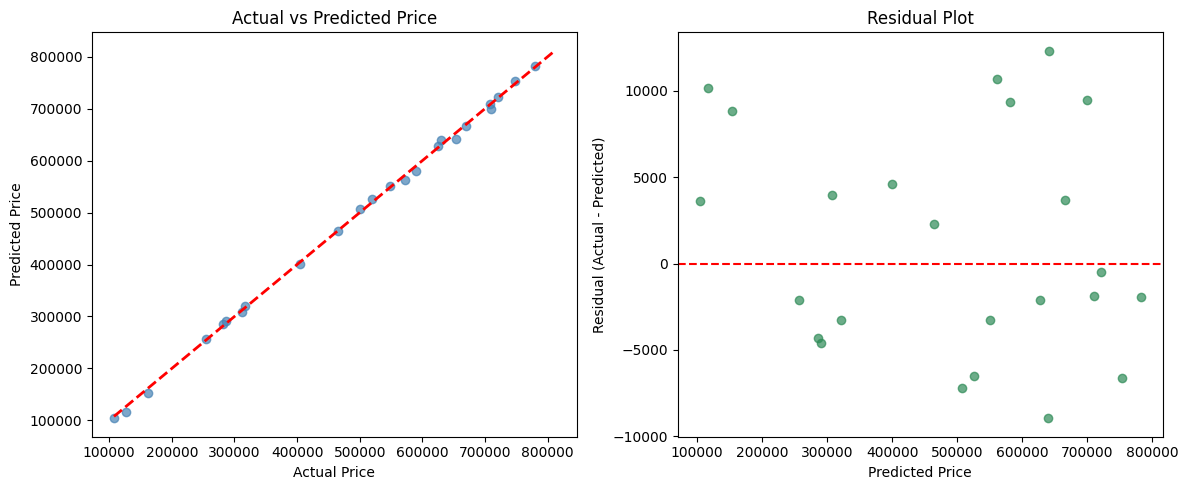

In [ ]:
# ---------------------------------------------------------------
# 5D: Multiple Linear Regression (House Price dataset)
# ---------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 1: Create a synthetic but realistic house-price dataset
np.random.seed(42)
n = 120

size = np.random.randint(500, 4000, n)          # square feet
bedrooms = np.random.randint(1, 6, n)
bathrooms = np.random.randint(1, 4, n)
distance = np.random.randint(1, 30, n)           # km from city center

price = (
    3000 * bedrooms
    + 5000 * bathrooms
    + 200 * size
    - 1500 * distance
    + np.random.randint(-10000, 10000, n)        # noise
)

house_data = pd.DataFrame({
    "Size_sqft": size,
    "Bedrooms": bedrooms,
    "Bathrooms": bathrooms,
    "Distance_km": distance,
    "Price": price,
})
print("Sample of the dataset:")
print(house_data.head())

# Step 2: Split into features (X) and target (y), then train/test split
X = house_data[["Size_sqft", "Bedrooms", "Bathrooms", "Distance_km"]]
y = house_data["Price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Step 3: Fit the Multiple Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 4: Predict and evaluate
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\nCoefficients (beta_1..beta_4): {np.round(model.coef_, 2)}")
print(f"Intercept (beta_0)            : {model.intercept_:.2f}")
print(f"Mean Squared Error (MSE)      : {mse:,.2f}")
print(f"R^2 Score                     : {r2:.4f}")

print("\nFitted regression equation:")
print(f"Price = {model.intercept_:.2f} "
      f"+ ({model.coef_[0]:.2f} * Size_sqft) "
      f"+ ({model.coef_[1]:.2f} * Bedrooms) "
      f"+ ({model.coef_[2]:.2f} * Bathrooms) "
      f"+ ({model.coef_[3]:.2f} * Distance_km)")

# Step 5: Visualize model fit
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, y_pred, color="steelblue", alpha=0.7)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--", lw=2)
axes[0].set_xlabel("Actual Price")
axes[0].set_ylabel("Predicted Price")
axes[0].set_title("Actual vs Predicted Price")

residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, color="seagreen", alpha=0.7)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_xlabel("Predicted Price")
axes[1].set_ylabel("Residual (Actual - Predicted)")
axes[1].set_title("Residual Plot")

plt.tight_layout()
plt.show()

# PRACTICAL NO. 6 — Numerical Methods

## 6A: Lagrange's Interpolation Method

**Theory**

Given $n$ data points $(x_0,y_0), \dots, (x_{n-1}, y_{n-1})$, **Lagrange interpolation**
constructs a polynomial that passes through *all* of them, without needing to solve a system
of equations directly:

$$P(x) = \sum_{i=0}^{n-1} y_i \cdot L_i(x), \qquad
L_i(x) = \prod_{j \neq i} \frac{x - x_j}{x_i - x_j}$$

Each **Lagrange basis polynomial** $L_i(x)$ equals 1 at $x=x_i$ and 0 at every other data
point, so the weighted sum reproduces every given $y_i$ exactly at its $x_i$.

**Applications:** Estimating in-between values from sparse experimental/sensor data,
constructing smooth curves through control points (CAD/graphics), numerical methods that
build higher-order approximations (e.g. numerical integration/differentiation formulas).


Interpolated value at x = 2.5 is y = 2.1953


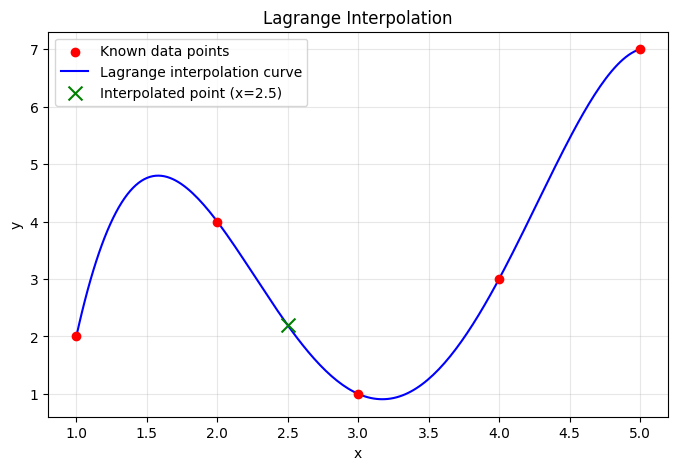

In [ ]:

# ---------------------------------------------------------------
# 6A: Lagrange's Interpolation Method
# ---------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt

def lagrange_interpolation(x_points, y_points, x_val):
    """
    Estimate y at x_val using Lagrange interpolation through the given points.
    x_points, y_points : known data points
    x_val               : the point at which to interpolate
    """
    n = len(x_points)
    result = 0.0
    for i in range(n):
        term = y_points[i]
        for j in range(n):
            if i != j:
                term *= (x_val - x_points[j]) / (x_points[i] - x_points[j])
        result += term
    return result

# Sample data points
x = np.array([1, 2, 3, 4, 5])
y = np.array([2, 4, 1, 3, 7])

x_new = 2.5
y_new = lagrange_interpolation(x, y, x_new)
print(f"Interpolated value at x = {x_new} is y = {y_new:.4f}")

# Build the full interpolating curve and plot it
x_range = np.linspace(min(x), max(x), 200)
y_range = [lagrange_interpolation(x, y, xi) for xi in x_range]

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color="red", zorder=5, label="Known data points")
plt.plot(x_range, y_range, color="blue", label="Lagrange interpolation curve")
plt.scatter([x_new], [y_new], color="green", zorder=5, marker="x", s=100,
            label=f"Interpolated point (x={x_new})")
plt.title("Lagrange Interpolation")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 6B: Newton's (Divided-Difference) Interpolation Method

**Theory**

**Newton's divided-difference interpolation** builds the same interpolating polynomial as
Lagrange, but incrementally, using a table of **divided differences**:

$$f[x_i] = y_i, \qquad f[x_i, \dots, x_{i+j}] = \frac{f[x_{i+1},\dots,x_{i+j}] - f[x_i,\dots,x_{i+j-1}]}{x_{i+j} - x_i}$$

The interpolating polynomial is then:

$$P(x) = f[x_0] + f[x_0,x_1](x-x_0) + f[x_0,x_1,x_2](x-x_0)(x-x_1) + \dots$$

**Advantage over Lagrange:** if a new data point is added, Newton's form only needs one more
term added to the table — the earlier terms don't need to be recomputed, unlike Lagrange's
formula which must be rebuilt from scratch.

**Applications:** Same as Lagrange (curve fitting, estimating unknown function values), and
preferred in situations where data points are added incrementally (e.g. streaming sensor data).


[[0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0]]
Divided-difference table (row i, column j = f[x_i,...,x_{i+j}]):
['1.0000', '3.0000', '1.0000', '0.0000']
['4.0000', '5.0000', '1.0000', '0.0000']
['9.0000', '7.0000', '0.0000', '0.0000']
['16.0000', '0.0000', '0.0000', '0.0000']

Interpolated value at x = 2.5 is 6.2500
(Exact x^2 value would be 6.25 - matches, since the data is exactly quadratic.)


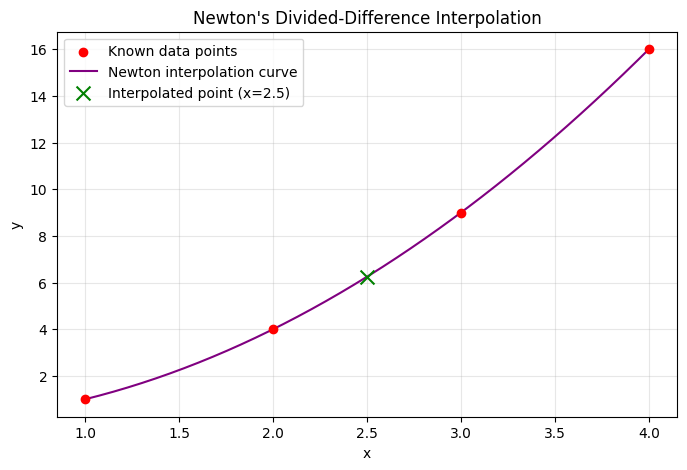

In [ ]:
# ---------------------------------------------------------------
# 6B: Newton's Divided-Difference Interpolation Method
# ---------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt

def divided_diff(x, y):
    """Build the divided-difference table. Returns the full n x n table."""
    n = len(y)
    table = [[0.0] * n for _ in range(n)]
    for i in range(n):
        table[i][0] = y[i]
    for j in range(1, n):   #j=1, 2, 3
        for i in range(n - j):  #0,1,2
            table[i][j] = (table[i + 1][j - 1] - table[i][j - 1]) / (x[i + j] - x[i])
    return table

print(table)

def newton_interpolation(x, y, value):
    """Estimate y at 'value' using Newton's divided-difference formula."""
    n = len(x)
    table = divided_diff(x, y)
    result = table[0][0]
    product_term = 1.0
    for i in range(1, n):
        product_term *= (value - x[i - 1])
        result += table[0][i] * product_term
    return result

# Example: f(x) = x^2, so interpolation should recover x^2 exactly (it's a degree-2 fit)
x_points = [1, 2, 3, 4]
y_points = [1, 4, 9, 16]     # x^2

# Show the divided-difference table for reference
table = divided_diff(x_points, y_points)
print("Divided-difference table (row i, column j = f[x_i,...,x_{i+j}]):")
for row in table:
    print(["%.4f" % v for v in row])

value_to_interpolate = 2.5
interpolated_value = newton_interpolation(x_points, y_points, value_to_interpolate)
print(f"\nInterpolated value at x = {value_to_interpolate} is {interpolated_value:.4f}")
print("(Exact x^2 value would be 6.25 - matches, since the data is exactly quadratic.)")

# Plot the interpolating curve
x_range = np.linspace(min(x_points), max(x_points), 200)
y_range = [newton_interpolation(x_points, y_points, xi) for xi in x_range]

plt.figure(figsize=(8, 5))
plt.scatter(x_points, y_points, color="red", zorder=5, label="Known data points")
plt.plot(x_range, y_range, color="purple", label="Newton interpolation curve")
plt.scatter([value_to_interpolate], [interpolated_value], color="green", marker="x",
            s=100, zorder=5, label=f"Interpolated point (x={value_to_interpolate})")
plt.title("Newton's Divided-Difference Interpolation")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
n = 4
table = [[0.0] * n for i in range(n)]
print(table)

[[0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0], [0.0, 0.0, 0.0, 0.0]]
